# Peggle Reinforcement Learning — Mid-Stage Report

## 1. Project Introduction

The final project will compare two reinforcement learning objectives:

1. **Orange-target agent:** clear every orange peg within a limited number of shots.
2. **All-peg agent:** clear every peg while minimizing shots.

**This mid-stage submission implements only the orange-target agent**, using Stable-Baselines3 Deep Q-Network (DQN) with `MlpPolicy`. The experiment uses one small, deterministic board with 3 orange pegs, 7 blue pegs, 21 launch angles, and at most 10 shots per episode. Blue pegs affect bounces but give no direct reward.

The contribution at this stage is an executable connection between PegglePy's physics, a Gymnasium environment, a learned policy, and a reproducible random baseline. It is an application of an established algorithm, not a claim of a new DQN algorithm.

**How to run:** select the project's `.venv/Scripts/python.exe` as this notebook's kernel in the IDE, install dependencies with `python -m pip install -r requirements.txt` using that interpreter, then select **Run All**. Python 3.12 is recommended. On a fresh setup, create a virtual environment first with `python -m venv .venv`.

The delivered notebook includes executed outputs. By default, Run All reuses the saved model and training logs and performs a fresh evaluation. Set `RUN_TRAINING = True` in the configuration cell to train a fresh model. Training and evaluation durations are configurable below; a 256-shot run is appropriate for a quick pipeline test.

Sources: [PegglePy repository](https://github.com/Mr0o/PegglePy), [SB3 DQN documentation](https://stable-baselines3.readthedocs.io/en/master/modules/dqn.html), and [Gymnasium environment documentation](https://gymnasium.farama.org/introduction/create_custom_env/). The downloaded PegglePy code retains its GPL-3.0 license in `local/PegglePy-main/LICENSE`.


### Setup and reproducibility

The supporting modules remain in `levels/`; the game source remains in `local/PegglePy-main/`. All paths are resolved from the notebook's project root. Fixed seeds control Python, NumPy, Torch, DQN exploration, and baseline action sampling. The board and physical transitions themselves are deterministic.

The optional environment variables provide a convenient way to test Run All without editing cells: `PEGGLE_TIMESTEPS`, `PEGGLE_EVAL_EPISODES`, `PEGGLE_RETRAIN=1`, and `PEGGLE_OUTPUT_DIR`. The last option can direct a quick test into a separate folder so that it does not replace the report's longer-run artifacts.


In [1]:
from pathlib import Path
import os
import sys
import json
import random
import subprocess

ROOT = Path.cwd().resolve()
if not (ROOT / "levels" / "peggle_env.py").exists() and (ROOT.parent / "levels" / "peggle_env.py").exists():
    ROOT = ROOT.parent
if not (ROOT / "local" / "PegglePy-main").exists():
    raise FileNotFoundError("Run this notebook from the Final Project folder.")
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))

import numpy as np
import pandas as pd
import torch
import matplotlib.pyplot as plt
from IPython.display import display, Markdown, Image

from levels.config_rl import CONFIG, SEED, N_ORANGE, experiment_id
from levels.peggle_env import PeggleEnv
from levels.visualize_data import export_data, level_inventory, plot_board, plot_original_board
from levels.train_dqn import train_agent, plot_training
from levels.evaluate import evaluate_agents, plot_comparison
from stable_baselines3 import DQN

TRAINING_TIMESTEPS = int(os.environ.get("PEGGLE_TIMESTEPS", "10000"))
EVALUATION_EPISODES = int(os.environ.get("PEGGLE_EVAL_EPISODES", "100"))
RUN_TRAINING = os.environ.get("PEGGLE_RETRAIN", "0") == "1"
OUTPUT_DIR = Path(os.environ.get("PEGGLE_OUTPUT_DIR", str(ROOT))).resolve()
RESULTS_DIR = OUTPUT_DIR / "results"
MODEL_PATH = OUTPUT_DIR / "models" / "dqn_orange.zip"
RESULTS_DIR.mkdir(parents=True, exist_ok=True)
MODEL_PATH.parent.mkdir(parents=True, exist_ok=True)

random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
torch.set_num_threads(1)
print(f"Interpreter: {sys.executable}")
print(f"Training budget if retraining: {TRAINING_TIMESTEPS:,} shots")
print(f"Evaluation: {EVALUATION_EPISODES} episodes per agent")
print(f"Output folder: {OUTPUT_DIR}")


Interpreter: C:\Users\sgeorge5\Downloads\CPE 595\Final Project\.venv\Scripts\python.exe
Training budget if retraining: 256 shots
Evaluation: 10 episodes per agent
Output folder: C:\Users\sgeorge5\Downloads\CPE 595\Final Project\results\notebook_smoke


## 2. Dataset Description

PegglePy contains 10 archived `.lvl` files. Inspection of `local/loadLevel.py` shows that each file stores a pickled list of **(x, y) coordinates only**. The loader centers the coordinate bounding box on the screen, constructs initially blue, unhit peg objects, and then normally assigns orange and green colors at runtime using `createPegColors`.

Therefore, archived colors and hit labels must not be invented. The table below explicitly distinguishes archived coordinates, centered coordinates, and the initial default state before color assignment. The export reads primitive coordinate data without invoking the game's GUI loader.

Our training board is a **separate hand-authored fixture**, not a full original level or a claimed subset. Its 10 coordinates and color assignments are fixed in `levels/config_rl.py`. Raw game-state records expose peg ID, position, color, hit status, visibility, and radius, matching the relevant PegglePy fields.

**There is no traditional labeled training dataset.** Training experience is generated by gameplay: each transition contains a state, a chosen angle, a measured reward, the next state, and whether the episode ended. DQN stores these transitions in its replay buffer. The archived levels and CSV exports describe board inputs; they are not supervised examples or labels.


In [2]:
board_data, original_data = export_data(RESULTS_DIR)
inventory = level_inventory()
display(inventory)
print(f"Original Level 1: {len(original_data)} peg coordinate records")
display(original_data.head(10))
print("Fixed training board, before the first shot:")
display(board_data)


,level,peg_count
0,Level 1.lvl,77
1,Level 2.lvl,94
2,Level 3.lvl,120
3,Level 4.lvl,137
4,Level 5.lvl,131
5,Level 6.lvl,149
6,Level 7.lvl,194
7,Level 8.lvl,172
8,Level 9.lvl,182
9,Level 10.lvl,211


Original Level 1: 77 peg coordinate records


,peg_id,archive_x,archive_y,x,y,color_before_assignment,initial_is_hit,color_stored_in_file
0,0,162.0,343.0,99.5,394.0,blue,False,False
1,1,168.0,373.0,105.5,424.0,blue,False,False
2,2,173.0,404.0,110.5,455.0,blue,False,False
3,3,178.0,434.0,115.5,485.0,blue,False,False
4,4,182.0,464.0,119.5,515.0,blue,False,False
5,5,187.0,494.0,124.5,545.0,blue,False,False
6,6,191.0,525.0,128.5,576.0,blue,False,False
7,7,194.0,555.0,131.5,606.0,blue,False,False
8,8,201.0,585.0,138.5,636.0,blue,False,False
9,9,209.0,614.0,146.5,665.0,blue,False,False


Fixed training board, before the first shot:


,peg_id,x,y,color,is_hit,is_visible,radius
0,0,420.0,300.0,orange,False,True,25.0
1,1,600.0,420.0,orange,False,True,25.0
2,2,800.0,300.0,orange,False,True,25.0
3,3,230.0,440.0,blue,False,True,25.0
4,4,350.0,550.0,blue,False,True,25.0
5,5,500.0,620.0,blue,False,True,25.0
6,6,690.0,600.0,blue,False,True,25.0
7,7,900.0,500.0,blue,False,True,25.0
8,8,1000.0,650.0,blue,False,True,25.0
9,9,600.0,720.0,blue,False,True,25.0


### Integration with PegglePy

| Source | Reused or adapted behavior |
| --- | --- |
| `local/vectors.py` | Original Vector class |
| `local/ball.py` | Original force, gravity, velocity cap, wall bounce, and floor-exit logic |
| `local/collision.py` | Original swept peg collision detection and response |
| `local/config.py` | Explicit matching defaults; settings/automatic installation are bypassed |
| `local/peg.py`, `run.py` | Lightweight peg state; hit pegs remain solid until shot end; deterministic stuck-peg removal |

The adapter redirects only upstream import names in memory into a private package. Vector, Ball, and collision function bodies execute unchanged. It does not import `run.py`, display code, audio, or any optimal-trajectory/zenball function. The downloaded game files are untouched.

The environment is a deliberately simplified task: no bucket catches, free balls, green pegs, power-ups, animations, or original score multipliers. The original game remains separate and can be launched from its own directory with `python run.py`.


## 3. Data Visualization

The first plot displays the original Level 1 positions after PegglePy's centering translation. Blue means the initial color **before** the game's runtime color assignment; the archive has no saved colors.

The second plot displays the actual training board. Orange circles are targets, blue circles are obstacles, and numbers are stable peg IDs. Pixel y increases downward, as in the game. Both plots are saved in `results/`; the required small-board image is `board_visualization.png`.


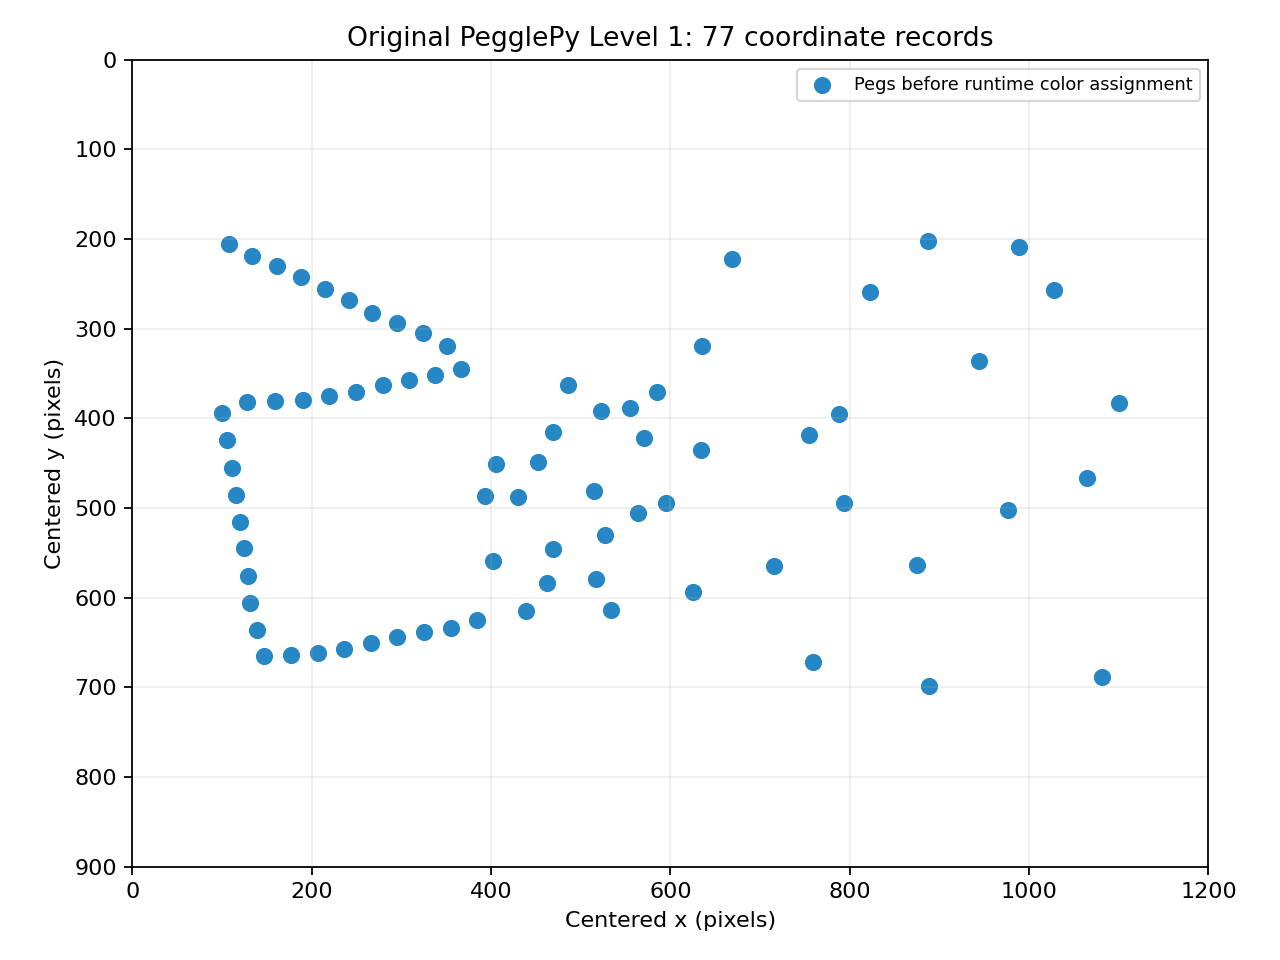

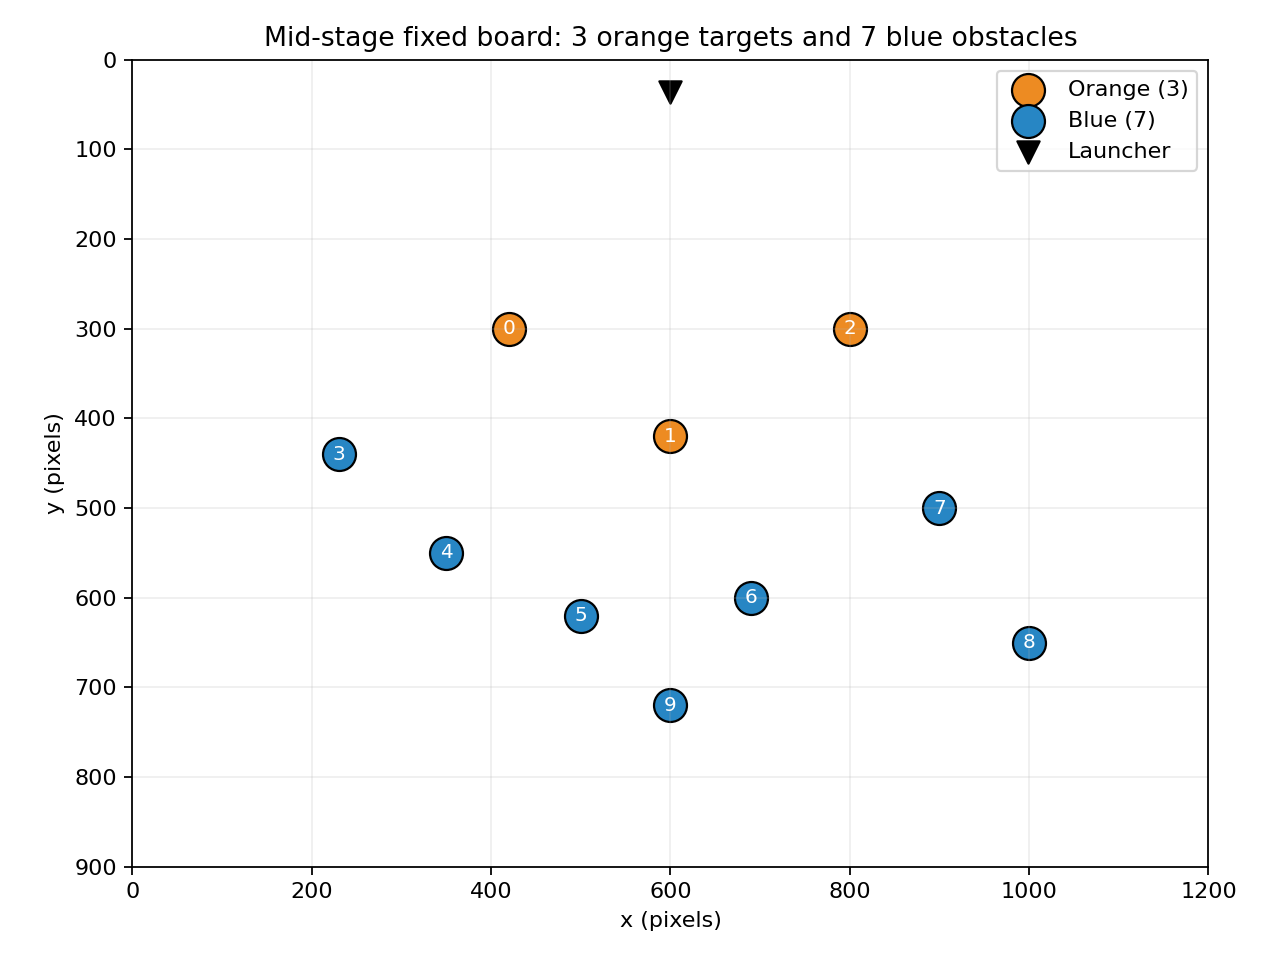

,peg_count,min_x,max_x,min_y,max_y
color,,,,,
blue,7,230.0,1000.0,440.0,720.0
orange,3,420.0,800.0,300.0,420.0


In [3]:
fig = plot_original_board(original_data, RESULTS_DIR / "original_board_visualization.png")
display(Image(filename=str(RESULTS_DIR / 'original_board_visualization.png')))
plt.close(fig)
fig = plot_board(board_data, RESULTS_DIR / "board_visualization.png")
display(Image(filename=str(RESULTS_DIR / 'board_visualization.png')))
plt.close(fig)
display(board_data.groupby("color").agg(peg_count=("peg_id", "size"),
                                      min_x=("x", "min"), max_x=("x", "max"),
                                      min_y=("y", "min"), max_y=("y", "max")))


## 4. Data Preprocessing

The observation is a fixed **41-element `float32` NumPy array**. Every peg retains its original slot after it is cleared, preventing shifting IDs or variable-length inputs.

| Feature per peg | Transformation | Meaning |
| --- | --- | --- |
| x coordinate | x / 1200 | Horizontal position in [0, 1] |
| y coordinate | y / 900 | Vertical position in [0, 1] |
| Orange indicator | 1 for orange; 0 for blue | Whether this peg is a target |
| Hit indicator | 1 once hit; 0 otherwise | Whether this peg has already been cleared |
| Final global feature | shots remaining / 10 | Fraction of the episode budget left |

The ten peg records are flattened in ID order, followed by the shot-budget feature: `10 × 4 + 1 = 41`. A blue peg is represented by an orange indicator of zero, so an additional blue indicator is unnecessary. Visibility is exported for inspection but redundant in a between-shot state and is not another model input.

Coordinates and color indicators remain available for cleared pegs. Between decisions, hit pegs have been removed from collision participation. Ball position and velocity are unnecessary in the observation because every decision begins with a fresh ball at the same launcher position. Since remaining shots are observed, the agent can distinguish otherwise identical boards with different remaining budgets.


In [4]:
env = PeggleEnv()
observation, initial_info = env.reset(seed=SEED)
feature_names = ["x_normalized", "y_normalized", "is_orange", "is_hit"]
normalized_pegs = pd.DataFrame(observation[:-1].reshape(10, 4), columns=feature_names)
normalized_pegs.insert(0, "peg_id", board_data.peg_id)
display(normalized_pegs)
print("Observation shape:", observation.shape, "dtype:", observation.dtype)
print("Normalized remaining shots:", observation[-1])
assert observation.shape == (41,) and observation.dtype == np.float32
assert env.observation_space.contains(observation)
display(pd.DataFrame([initial_info]))


,peg_id,x_normalized,y_normalized,is_orange,is_hit
0,0,0.350000,0.333333,1.0,0.0
1,1,0.500000,0.466667,1.0,0.0
2,2,0.666667,0.333333,1.0,0.0
3,3,0.191667,0.488889,0.0,0.0
4,4,0.291667,0.611111,0.0,0.0
5,5,0.416667,0.688889,0.0,0.0
6,6,0.575000,0.666667,0.0,0.0
7,7,0.750000,0.555556,0.0,0.0
8,8,0.833333,0.722222,0.0,0.0
9,9,0.500000,0.800000,0.0,0.0


Observation shape: (41,) dtype: float32
Normalized remaining shots: 1.0


,orange_remaining,orange_cleared,success,shots_remaining,shots_used,simulation_timeouts,stuck_removals
0,3,0,False,10,0,0,0


### Inspect a real transition

This cell launches one straight-down shot only to demonstrate preprocessing and reward accounting. This diagnostic action is not supplied as an expert label and does not choose actions for training. The next state should retain the same position/color slots while updating hit indicators and the remaining budget.


In [5]:
next_observation, reward, terminated, truncated, shot_info = env.step(10)
display(pd.DataFrame(env.board_records()))
display(pd.DataFrame([shot_info]))
print("Observed reward:", reward)
print("Remaining shot feature:", next_observation[-1])
assert next_observation[-1] == np.float32(0.9)
assert reward == (CONFIG.orange_reward * shot_info["new_orange_cleared"]
                  - CONFIG.shot_penalty
                  + (CONFIG.completion_bonus if shot_info["success"] else 0))
env.close()


,peg_id,x,y,color,is_hit,is_visible,radius
0,0,420.0,300.0,orange,False,True,25.0
1,1,600.0,420.0,orange,True,False,25.0
2,2,800.0,300.0,orange,False,True,25.0
3,3,230.0,440.0,blue,False,True,25.0
4,4,350.0,550.0,blue,False,True,25.0
5,5,500.0,620.0,blue,False,True,25.0
6,6,690.0,600.0,blue,False,True,25.0
7,7,900.0,500.0,blue,False,True,25.0
8,8,1000.0,650.0,blue,False,True,25.0
9,9,600.0,720.0,blue,True,False,25.0


,orange_remaining,orange_cleared,success,shots_remaining,shots_used,simulation_timeouts,stuck_removals,new_orange_cleared,angle_degrees,simulation_frames,shot_timed_out,terminal_reason
0,2,1,False,9,1,0,2,1,0.0,3543,False,None


Observed reward: 9.0
Remaining shot feature: 0.9


## 5. DQN Implementation and Training

### Task and environment

One environment step launches and finishes **one complete shot**, including all bounces. Actions 0 through 20 map to equally spaced angles from **−60° to +60° relative to downward vertical**, in increments of 6°. Negative angles aim left, positive angles right. Launch force, gravity, ball radius, peg radius, velocity cap, and screen size match PegglePy's defaults.

The per-shot reward is:

`reward = 10 × newly cleared orange pegs − 1 + 25 × episode success`

Blue hits give no direct reward. Each shot incurs the penalty, and the completion bonus is awarded once. The episode terminates after clearing all 3 orange pegs or using 10 shots. Exhausting shots is a terminal failure within the finite task, not an external time-limit truncation.

Hit pegs remain solid during the current shot and are removed before the next decision. A simulation-tick counter replaces the original game's wall-clock stuck-peg timer. A 10,000-frame safety guard prevents an infinite shot; any forced shot endings are logged as simulation timeouts. These should be checked when interpreting results.

### Learning algorithm

DQN learns action values from gameplay transitions using a replay buffer and a periodically updated target network. Its MLP maps 41 state features to 21 estimated action values. Epsilon-greedy exploration selects random actions early in training; evaluation uses greedy, deterministic predictions.

This experiment uses one initial configuration: two hidden layers of 64 units, learning rate 0.001, discount 0.99, replay capacity 20,000, batch size 64, 200 learning-start steps, one gradient update every 4 shots, and target-network updates every 500 shots. Epsilon decreases from 1.0 to 0.05 over the first 60% of training. No hyperparameter search or action oracle is used.


In [6]:
from gymnasium.utils.env_checker import check_env as gymnasium_check
from stable_baselines3.common.env_checker import check_env as sb3_check

gymnasium_check(PeggleEnv(), skip_render_check=True)
sb3_check(PeggleEnv(), warn=True)
print("Gymnasium and Stable-Baselines3 environment checks passed.")
display(pd.DataFrame({"action": np.arange(CONFIG.n_actions),
                      "angle_from_downward_vertical": CONFIG.angles_degrees}))


Gymnasium and Stable-Baselines3 environment checks passed.


,action,angle_from_downward_vertical
0,0,-60.0
1,1,-54.0
2,2,-48.0
3,3,-42.0
4,4,-36.0
5,5,-30.0
6,6,-24.0
7,7,-18.0
8,8,-12.0
9,9,-6.0


### Train or load the recorded initial model

`train_agent` in `levels/train_dqn.py` creates a **Stable-Baselines3 `DQN("MlpPolicy", ...)`** model, calls `learn(total_timesteps=...)`, records completed episodes, and saves the model. The implementation stays outside the notebook so game logic and logging do not obscure the report.

A timestep means one complete shot, not one animation frame or one episode. A 256-shot smoke run was performed before the longer initial run. Training duration affects the exploration schedule, so the longer run is a fresh training experiment with the same seed and fixed settings, not a continuation of the smoke model.

To repeat training, set `RUN_TRAINING = True` in the configuration cell. Retraining replaces the selected output folder's model and logs. Run All with the default setting loads the supplied artifacts, displays their actual training duration, and evaluates them again. If the model is absent, this cell trains automatically.


In [7]:
if RUN_TRAINING or not MODEL_PATH.exists():
    model, training_metadata = train_agent(
        total_timesteps=TRAINING_TIMESTEPS, seed=SEED,
        model_path=MODEL_PATH, results_dir=RESULTS_DIR, verbose=0,
    )
    print("Trained and saved a fresh model.")
else:
    training_metadata = json.loads((RESULTS_DIR / "training_metadata.json").read_text(encoding="utf-8"))
    if training_metadata["experiment_id"] != experiment_id():
        raise ValueError("Saved conditions differ; retrain for the current environment.")
    model = DQN.load(MODEL_PATH, device="cpu")
    print("Loaded the saved model and its measured training logs.")

display(pd.DataFrame([{
    "algorithm": training_metadata["algorithm"],
    "policy": training_metadata["policy"],
    "training_shots": training_metadata["actual_timesteps"],
    "completed_episodes": training_metadata["completed_episodes"],
    "training_seconds": training_metadata["elapsed_seconds"],
    "seed": training_metadata["seed"],
}]))
display(pd.DataFrame(training_metadata["versions"].items(), columns=["package", "tested_version"]))
print("Model:", MODEL_PATH)


Trained and saved a fresh model.


,algorithm,policy,training_shots,completed_episodes,training_seconds,seed
0,Stable-Baselines3 DQN,MlpPolicy,256,34,0.380319,42


,package,tested_version
0,numpy,1.26.4
1,torch,2.12.1
2,gymnasium,1.4.0
3,stable-baselines3,2.9.2
4,matplotlib,3.10.7
5,pandas,3.0.2


Model: C:\Users\sgeorge5\Downloads\CPE 595\Final Project\results\notebook_smoke\models\dqn_orange.zip


## 6. Preliminary Results

### Measured training progress

The CSV contains one row per **completed** training episode: cumulative training shots, episode return, shots used, orange pegs cleared, success, simulation timeouts, and stuck-peg removals. No performance figures are supplied by hand.

The learning curves show raw returns, a rolling mean, and rolling training success. Training includes exploratory actions; these curves are not a separate test score. The early/late table describes this run rather than proving statistical significance.


,episode,timesteps,episode_reward,shots_used,orange_cleared,success,simulation_timeouts,stuck_removals
0,1,6,49.0,6,3,True,0,0
1,2,16,10.0,10,2,False,0,0
2,3,19,52.0,3,3,True,0,2
3,4,20,54.0,1,3,True,0,0
4,5,28,47.0,8,3,True,0,2


,period,episodes,mean_return,success_pct,mean_orange_cleared
0,First completed episodes,34,33.294118,58.823529,2.588235
1,Last completed episodes,34,33.294118,58.823529,2.588235


Training simulation timeouts: 0


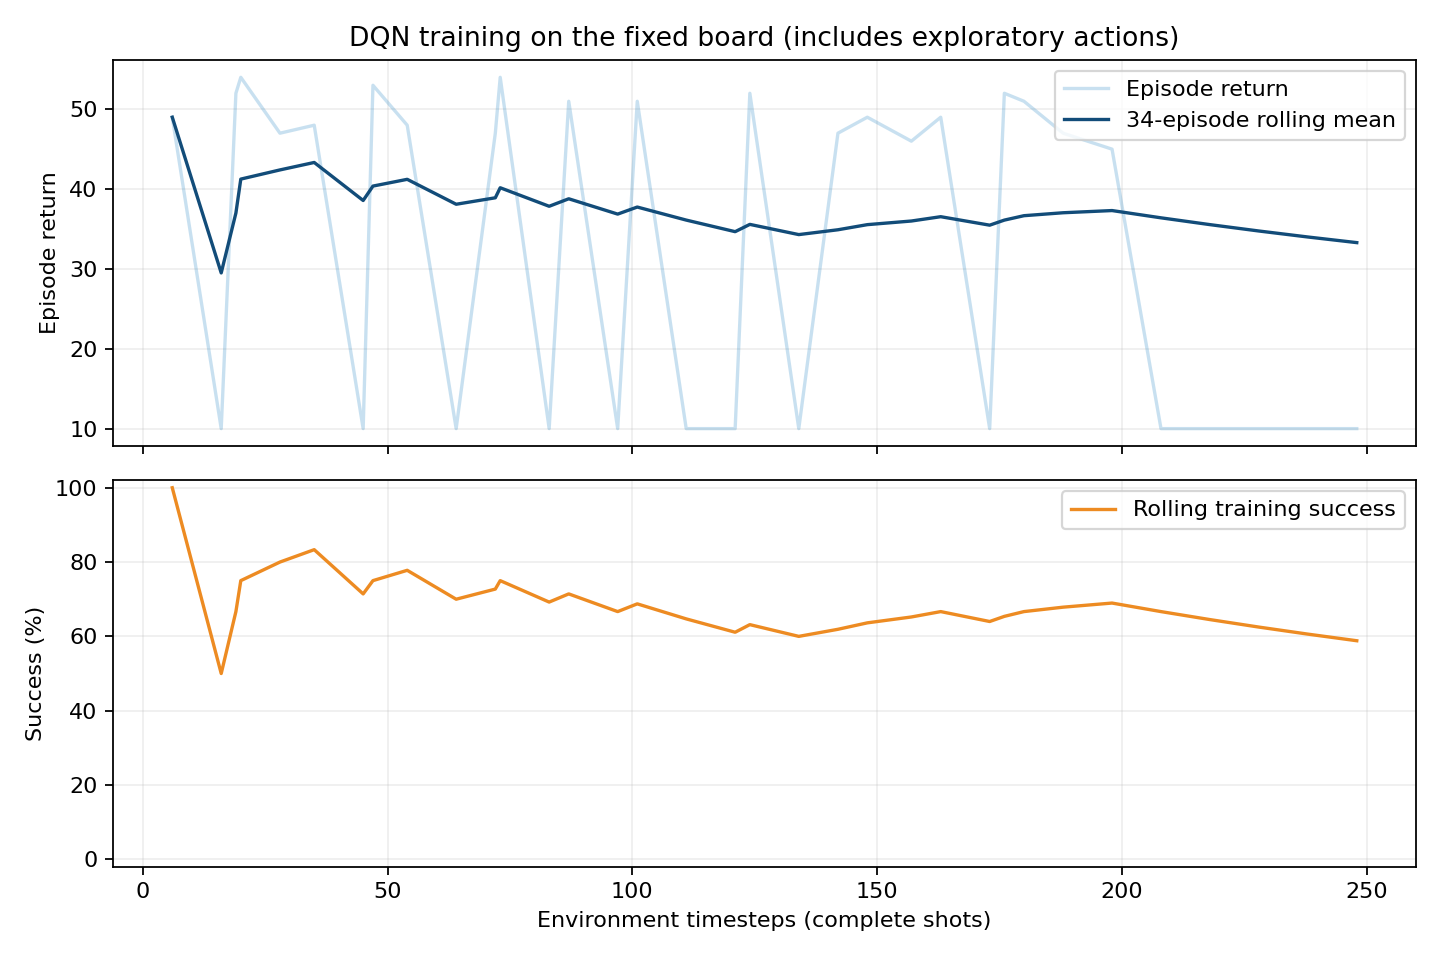

In [8]:
training_log = pd.read_csv(RESULTS_DIR / "training_episodes.csv")
display(training_log.head())
window = min(100, len(training_log))
if window:
    progress = []
    for label, data in [("First completed episodes", training_log.head(window)),
                        ("Last completed episodes", training_log.tail(window))]:
        progress.append({"period": label, "episodes": len(data),
                         "mean_return": data.episode_reward.mean(),
                         "success_pct": 100 * data.success.mean(),
                         "mean_orange_cleared": data.orange_cleared.mean()})
    display(pd.DataFrame(progress))
print("Training simulation timeouts:", int(training_log.simulation_timeouts.sum()))
fig = plot_training(RESULTS_DIR / "training_episodes.csv", RESULTS_DIR / "training_rewards.png")
display(Image(filename=str(RESULTS_DIR / 'training_rewards.png')))
plt.close(fig)


### DQN versus random shooting

Both agents use the **same fixed board, observation, physics, 21 angles, reward definition, and 10-shot budget**. Each evaluation episode begins with the same untouched board. The DQN predicts with `deterministic=True`; the baseline samples each action uniformly from the same 21 options. Seeds 10042 onward control random action sequences.

Metrics are computed from the saved episode rows:

- **Success rate:** successful episodes / all evaluated episodes.
- **Orange pegs cleared:** mean of cleared orange pegs / 3 across all episodes, expressed as a percentage.
- **Average shots in successful games:** mean shots conditioned on success; missing if there are no successes.
- Average shots across all games and mean episode return are also retained in the CSV.

Conditional shot averages have different successful-game subsets for the two agents. Interpret them together with success rate. There is no classification accuracy metric in this task.

**Evaluation scope:** this is an in-sample fixed-board experiment. The deterministic DQN repeats exactly the same trajectory across episodes, so 100 DQN episodes are not 100 independent board challenges. Evaluation seeds change baseline actions, not board layouts. The current small board can be solved by a fixed angle; success here cannot establish multi-board generalization or sophisticated planning.


,agent,episodes,successes,success_rate_pct,orange_cleared_pct,avg_shots_success,avg_shots_all,mean_episode_reward,simulation_timeouts
0,DQN,10,0,0.0,66.667,NaN,10.0,10.0,0
1,Random,10,8,80.0,93.333,4.75,5.8,42.2,0


,agent,episode,seed,episode_reward,success,orange_cleared,orange_cleared_pct,shots_used,simulation_timeouts,stuck_removals
0,DQN,1,10042,10.0,False,2,66.666667,10,0,0
1,DQN,2,10043,10.0,False,2,66.666667,10,0,0
2,DQN,3,10044,10.0,False,2,66.666667,10,0,0
3,DQN,4,10045,10.0,False,2,66.666667,10,0,0
4,DQN,5,10046,10.0,False,2,66.666667,10,0,0


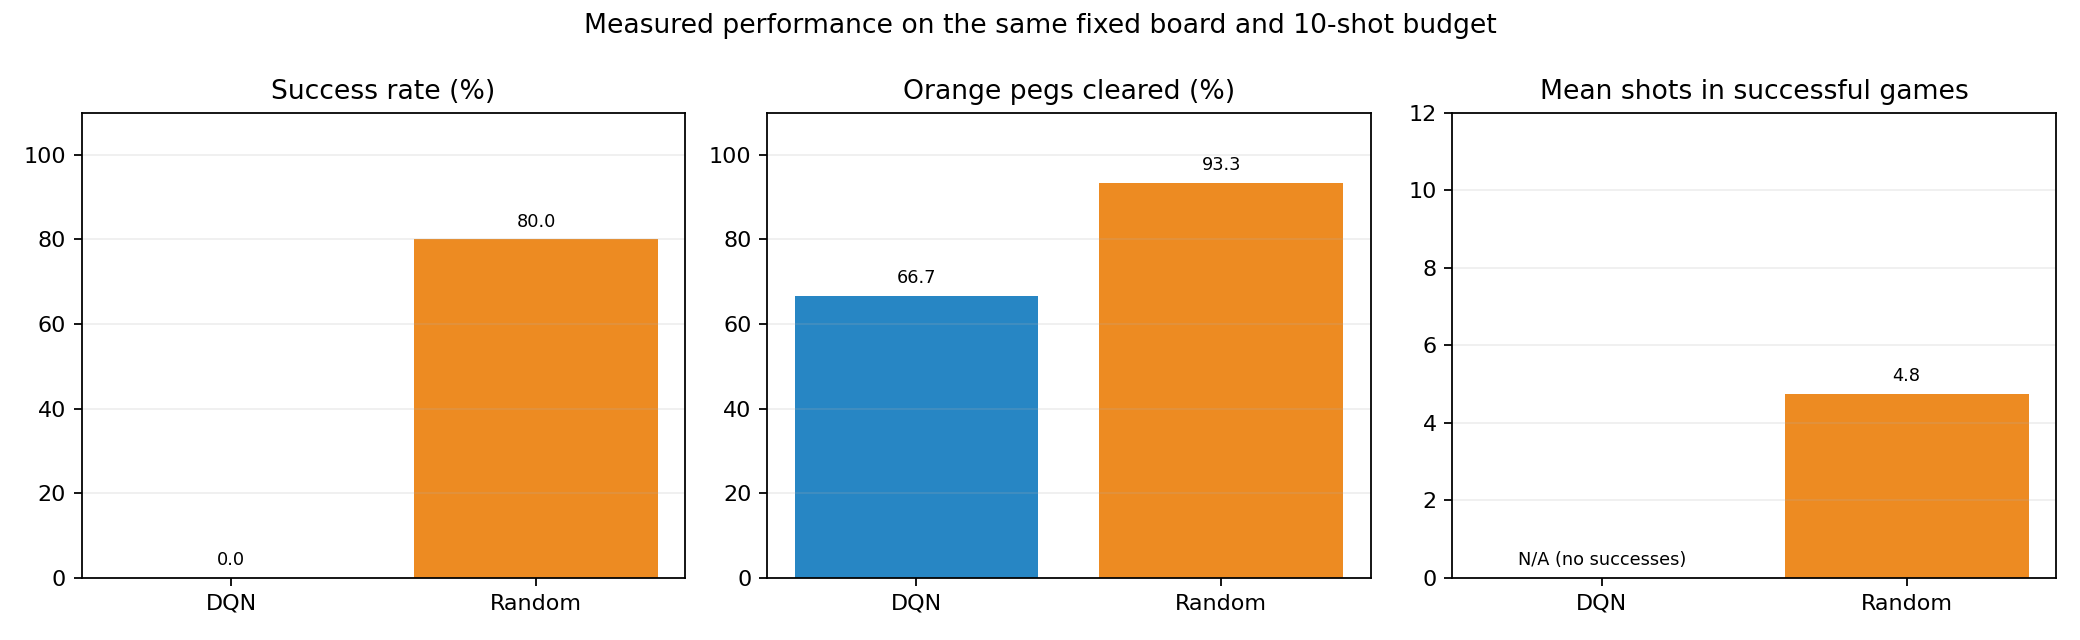

Evaluation CSVs:
C:\Users\sgeorge5\Downloads\CPE 595\Final Project\results\notebook_smoke\results\evaluation_summary.csv
C:\Users\sgeorge5\Downloads\CPE 595\Final Project\results\notebook_smoke\results\evaluation_episodes.csv
C:\Users\sgeorge5\Downloads\CPE 595\Final Project\results\notebook_smoke\results\evaluation_shots.csv


In [9]:
summary, evaluation_episodes = evaluate_agents(
    model_path=MODEL_PATH, episodes=EVALUATION_EPISODES, seed=SEED + 10000,
    results_dir=RESULTS_DIR,
)
display(summary.round(3))
display(evaluation_episodes.head())
fig = plot_comparison(summary, RESULTS_DIR / "dqn_vs_random.png")
display(Image(filename=str(RESULTS_DIR / 'dqn_vs_random.png')))
plt.close(fig)
print("Evaluation CSVs:", RESULTS_DIR / "evaluation_summary.csv",
      RESULTS_DIR / "evaluation_episodes.csv", RESULTS_DIR / "evaluation_shots.csv", sep="\n")


### Interpretation grounded in the current files

The following text is generated from the measured evaluation table, so it remains accurate after a shorter rerun. The shot table shows which initial action the saved DQN actually chooses. A successful repeated action is evidence of solving this board, with no inference about unseen levels.


In [10]:
dqn_row = summary.set_index("agent").loc["DQN"]
random_row = summary.set_index("agent").loc["Random"]
if dqn_row.success_rate_pct > random_row.success_rate_pct:
    conclusion = "The saved DQN outperformed random shooting in this measured fixed-board test."
elif dqn_row.success_rate_pct < random_row.success_rate_pct:
    conclusion = "The saved DQN underperformed random shooting; this run does not support a better policy."
else:
    conclusion = "The saved DQN and random baseline had the same measured success rate."

dqn_shots = "N/A (no successful games)" if pd.isna(dqn_row.avg_shots_success) else f"{dqn_row.avg_shots_success:.2f}"
display(Markdown(
    f"**Measured outcome:** DQN success **{dqn_row.success_rate_pct:.1f}%**, "
    f"orange pegs cleared **{dqn_row.orange_cleared_pct:.1f}%**, "
    f"mean shots in successful games **{dqn_shots}**. "
    f"Random success **{random_row.success_rate_pct:.1f}%**, "
    f"orange pegs cleared **{random_row.orange_cleared_pct:.1f}%**. "
    f"{conclusion} These measurements apply only to the configured deterministic board."
))
shot_log = pd.read_csv(RESULTS_DIR / "evaluation_shots.csv")
display(shot_log[(shot_log.agent == "DQN") & (shot_log.shot == 1)]
        [["action", "angle_degrees", "new_orange_cleared", "simulation_frames"]].drop_duplicates())
assert int(summary.simulation_timeouts.sum()) == 0, "Inspect timed-out shots before interpreting these results."

smoke_path = ROOT / "results" / "smoke" / "evaluation_summary.csv"
if smoke_path.exists():
    print("Earlier 256-shot pipeline smoke evaluation (10 episodes per agent):")
    display(pd.read_csv(smoke_path).round(3))
    display(Markdown("The smoke run tested the pipeline. It is retained even if its policy performs poorly; it is not substituted for the longer run."))


**Measured outcome:** DQN success **0.0%**, orange pegs cleared **66.7%**, mean shots in successful games **N/A (no successful games)**. Random success **80.0%**, orange pegs cleared **93.3%**. The saved DQN underperformed random shooting; this run does not support a better policy. These measurements apply only to the configured deterministic board.

,action,angle_degrees,new_orange_cleared,simulation_frames
0,18,48.0,2,1074


Earlier 256-shot pipeline smoke evaluation (10 episodes per agent):


,agent,episodes,successes,success_rate_pct,orange_cleared_pct,avg_shots_success,avg_shots_all,mean_episode_reward,simulation_timeouts
0,DQN,10,0,0.0,66.667,NaN,10.0,10.0,0
1,Random,10,8,80.0,93.333,4.75,5.8,42.2,0


The smoke run tested the pipeline. It is retained even if its policy performs poorly; it is not substituted for the longer run.

### Verification

The focused suite checks reset and normalization; all 21 shot actions; physical hits and reward accounting; prevention of repeated orange rewards; completion bonus; budget exhaustion; invalid actions; reproducibility; Gymnasium/SB3 compatibility; actual DQN weight updates; model serialization; and the consistency of saved evaluation metrics. It also verifies that the adapter does not import graphical game modules or create game settings.

The next cell runs these checks with this notebook's interpreter. It raises an error if a test fails.


In [11]:
test_run = subprocess.run(
    [sys.executable, "-m", "pytest", str(ROOT / "levels" / "test_environment.py"), "-q"],
    cwd=ROOT, capture_output=True, text=True,
)
print(test_run.stdout)
if test_run.returncode:
    print(test_run.stderr)
test_run.check_returncode()


...............................                                          [100%]
31 passed in 3.88s



## 7. Novel Solution and Future Work

The current solution turns an interactive Peggle clone into a headless, shot-level RL task. It preserves the original ball/collision mechanics, represents changing boards in a fixed-size state vector, trains one DQN agent from self-generated gameplay, and compares it with uniformly random actions under matched conditions. The report artifacts include the raw board exports, actual episode logs, model settings and package versions, model checkpoint, learning curves, and evaluation tables.

**Current limitations**

- One deliberately easy fixed board and one training seed; a single angle can solve the board. The result does not demonstrate a general strategy, independent statistical evidence across boards, or optimality of the policy.
- Compact numerical observations use known peg positions and colors rather than image perception.
- The original bucket, free balls, power-ups, score system, and graphics are omitted. The adapter uses a fixed simulation tick and deterministic stuck removal; it is not a complete reproduction of every original gameplay effect.
- The simulator retains the upstream sampled collision behavior and its numerical limitations. Forced shot endings are explicitly logged; results should be inspected if timeouts occur.
- Only a short smoke run and one longer initial configuration were trained. No hyperparameter optimization, multiple-seed study, held-out level testing, or advanced demonstrations were performed.
- Training-return changes are influenced by decreasing exploration, and the successful-game shot average is conditional on success.

**Reserved for the final project**

The second agent will eventually change the target from orange pegs to **all remaining pegs**, with a reward and terminal rule that explicitly encourage using fewer shots. That will require a separately defined task and separately trained policy before a meaningful comparison of the two objectives. **No second environment objective or second agent is implemented in this submission.**

Full-size and multiple-level training, held-out board evaluation, multiple training seeds, hyperparameter optimization, more complete game mechanics, advanced visual demonstrations, and comparisons between both objectives remain future work.

**Artifacts:** `models/dqn_orange.zip`; `results/board_data.csv`; `results/original_level_data.csv`; `results/board_visualization.png`; `results/original_board_visualization.png`; `results/training_episodes.csv`; `results/training_rewards.png`; `results/evaluation_summary.csv`; `results/evaluation_episodes.csv`; `results/evaluation_shots.csv`; `results/dqn_vs_random.png`; and the training/evaluation metadata JSON files.
